# 03 · Modelado

Parte del parquet de `02_data_panel_modelos.ipynb` (`data/processed/datos_modelo_estrato.parquet`, una fila por estrato y edición, con datos reales).

1. **Cuánta variación hay en cada variable**: entre países, entre ediciones y entre estratos.
2. **Selección simple de variables**, sin usar la nota: fuera las que miden el tamaño del país y las redundantes.
3. **Modelo baseline por asignatura**: un XGBoost para matemáticas, otro para lectura y otro para ciencias, con una partición train/test 80/20 estratificada por país.
4. **SHAP** de los tres modelos sobre el test: qué variables pesan más en cada predicción.
5. **Guardado** de los tres modelos en `data/models`, y, para el LLM, de los tres modelos, sus columnas y sus explicadores SHAP en `agente_llm/data_llm`.

`CNT` solo sirve para separar por país al validar; no es una variable del modelo.

In [1]:
import os
import joblib
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import GroupKFold, train_test_split
from xgboost import XGBRegressor

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.utils_pisa import establecer_semilla

establecer_semilla(42)
pd.set_option('display.float_format', lambda valor: f'{valor:.2f}')

ruta_datos_procesados = Path('../../data/processed')
datos = pd.read_parquet(ruta_datos_procesados / 'datos_modelo_estrato.parquet')

columnas_objetivo = {'matemáticas': 'media_math_estrato', 'lectura': 'media_read_estrato', 'ciencias': 'media_scie_estrato'}
# Variables candidatas que guarda el 02 (interacciones, brecha de apoyo y retardos del gasto): no entran al modelo baseline
variables_candidatas = ['escudo_equidad_deberes', 'gasto_efectivo_refuerzo', 'calidad_refuerzo_escolar', 'deberes_x_desarrollo', 'deberes_x_escs',
                        'brecha_apoyo_local', 'gasto_alumno_edicion_anterior', 'variacion_gasto_ediciones_previas_pct', 'variacion_gasto_ultima_edicion_pct']
faltan = sorted(set(list(columnas_objetivo.values()) + variables_candidatas + ['CNT', 'year']) - set(datos.columns))
assert not faltan, f'Columnas que no están en el parquet (volver a ejecutar 02_data_panel_modelos): {faltan}'
variables_disponibles = [columna for columna in datos.columns if columna not in ['CNT', *columnas_objetivo.values(), *variables_candidatas]]
print(f'{datos.shape[0]} estratos-edición; {len(variables_disponibles)} variables disponibles para el modelo (sin CNT, objetivos ni candidatas)')
print('Estratos sin nota, por asignatura:', {asignatura: int(datos[columna].isna().sum()) for asignatura, columna in columnas_objetivo.items()})

✅ Semillas del proyecto establecidas con éxito (seed=42).
2328 estratos-edición; 46 variables disponibles para el modelo (sin CNT, objetivos ni candidatas)
Estratos sin nota, por asignatura: {'matemáticas': 0, 'lectura': 0, 'ciencias': 0}


## Cuánta variación hay en cada variable

Cada variable del panel por estrato varía a un nivel distinto: las de presupuesto, PIB y Gini son del **país y la edición** (todos sus estratos comparten el valor), mientras que las notas, el `ESCS`, los deberes y el personal de apoyo se calculan **por estrato**. Para cada una se reparte la varianza total (cada fila del panel pesa igual) en tres partes que suman 100 %:

* **entre países**: diferencias entre las medias de los países;
* **entre ediciones**: cuánto se separa la media de un país en una edición de su media en las cuatro;
* **entre estratos**: lo que varía entre los estratos de un mismo país y edición.

Los estratos de 2022 tienen otro código que los de 2012-2018, por lo que parte de la variación «entre estratos» incluye cambios de definición de los estratos.

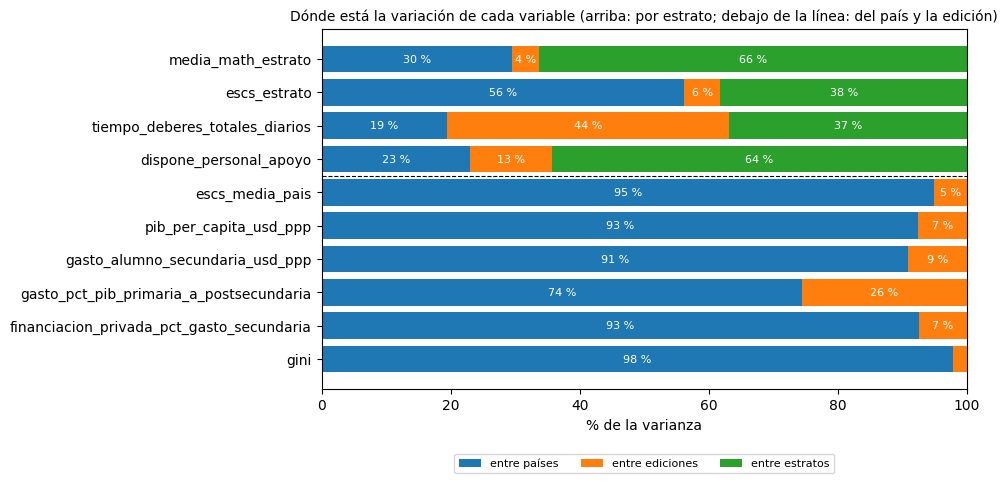

In [2]:
def descomposicion_varianza(panel, variables):
    """% de la varianza de cada variable entre países, entre ediciones (dentro del país) y entre estratos (dentro de país y edición)."""
    filas = {}
    for variable in variables:
        datos_variable = panel[['CNT', 'year', variable]].dropna()
        total = ((datos_variable[variable] - datos_variable[variable].mean()) ** 2).sum()
        media_pais = datos_variable.groupby('CNT')[variable].transform('mean')
        media_pais_edicion = datos_variable.groupby(['CNT', 'year'])[variable].transform('mean')
        filas[variable] = {'entre países': ((media_pais - datos_variable[variable].mean()) ** 2).sum() / total,
                    'entre ediciones': ((media_pais_edicion - media_pais) ** 2).sum() / total,
                    'entre estratos': ((datos_variable[variable] - media_pais_edicion) ** 2).sum() / total}
    return 100 * pd.DataFrame(filas).T


variables_estrato = ['media_math_estrato', 'escs_estrato', 'tiempo_deberes_totales_diarios', 'dispone_personal_apoyo']
variables_pais_edicion = ['escs_media_pais', 'pib_per_capita_usd_ppp', 'gasto_alumno_secundaria_usd_ppp', 'gasto_pct_pib_primaria_a_postsecundaria', 'financiacion_privada_pct_gasto_secundaria', 'gini']
reparto_varianza = descomposicion_varianza(datos, variables_estrato + variables_pais_edicion)

fig, ax = plt.subplots(figsize=(10, 5))
acumulado = pd.Series(0.0, index=reparto_varianza.index)
for componente, color in zip(reparto_varianza.columns, ['tab:blue', 'tab:orange', 'tab:green']):
    barras = ax.barh(reparto_varianza.index, reparto_varianza[componente], left=acumulado, color=color, label=componente)
    ax.bar_label(barras, labels=[f'{porcentaje:.0f} %' if porcentaje >= 4 else '' for porcentaje in reparto_varianza[componente]], label_type='center', fontsize=8, color='white')
    acumulado += reparto_varianza[componente]
ax.axhline(len(variables_estrato) - 0.5, color='black', lw=0.8, ls='--')
ax.invert_yaxis()
ax.set_xlabel('% de la varianza')
ax.set_title('Dónde está la variación de cada variable (arriba: por estrato; debajo de la línea: del país y la edición)', fontsize=10)
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.25), fontsize=8)
plt.tight_layout()
plt.show()

### Qué implica para el modelo

* **Presupuesto, PIB y Gini son contexto de país.** Más del 90 % de su variación es entre países (gasto por alumno 91 %, financiación privada 93 %, Gini 98 %) y ninguna entre estratos: los estratos de un país y edición repiten el mismo valor. Su información equivale a unos 33 países, no a 2 328 filas (muestra efectiva: `01_EDA_presupuestos.ipynb`), así que repetirlos en cada estrato no aumenta la muestra y con ellos solo se pueden estudiar asociaciones entre países, no el efecto de cambiar el presupuesto.
* **Las variables de estrato sí varían dentro del país** y esa es la variación con la que el modelo puede discriminar entre filas de un mismo grupo de países: el 64 % de `dispone_personal_apoyo`, el 66 % de la nota media, el 38 % del `ESCS` y el 37 % de las horas de deberes es entre estratos. Por eso la tabla por estratos usa `escs_estrato` y no solo la media del país (`escs_media_pais`, 95 % entre países).
* **El `ESCS` casi no cambia entre ediciones** (6 %), a diferencia de los deberes (44 %). En los deberes ese cambio no es real: cada edición mide un constructo distinto (ver «Indicadores de deberes» en `02_data_panel_modelos`).
* **Consecuencias**: el perfil macroeconómico y el presupuesto sitúan al estrato en un grupo de países; lo que distingue a los estratos dentro de ese grupo son el `ESCS`, los deberes y el apoyo. Al validar, conviene separar por **país** y no por filas, porque los estratos de un mismo país se parecen entre sí.

## Selección simple de variables

Dos reglas que **no usan la nota**, así que no hay riesgo de elegir variables a medida de los datos:

1. **Fuera las variables que miden el tamaño del país**: la población y los totales de gasto de secundaria (corriente, capital, personal y docentes). Son mayores en los países grandes, no en los que gastan más por alumno; el esfuerzo de gasto ya lo recogen las variables por alumno, en % o relativas.
2. **Fuera las redundantes**: de cada par de variables con |r| ≥ 0,9 se queda una. Se recorren empezando por `gasto_alumno_secundaria_usd_ppp`, la variable principal del gasto según `01_EDA_presupuestos` (gasto por alumno de toda la secundaria, porque según el país los alumnos de 15 años están en una etapa u otra), y después de la que tiene menos nulos a la que más (a igualdad, en el orden del parquet). Una variable se descarta si se parece tanto a otra ya elegida. Dos variables casi iguales no aportan información nueva al modelo y, además, se reparten la importancia en SHAP, lo que confunde la interpretación.

Con `USAR_TODAS_LAS_VARIABLES = True` el modelo usa todas las disponibles, sin estas dos reglas.

In [3]:
USAR_TODAS_LAS_VARIABLES = False
UMBRAL_REDUNDANCIA = 0.9
variables_tamaño_pais = ['poblacion', 'gasto_total_corriente_secundaria_usd_ppp', 'gasto_total_capital_secundaria_usd_ppp',
                         'gasto_total_personal_secundaria_usd_ppp', 'gasto_total_docentes_secundaria_usd_ppp']

VARIABLES_PRIORITARIAS = ['gasto_alumno_secundaria_usd_ppp']   # variable principal del gasto (01_EDA_presupuestos): se considera la primera

# Regla 2: primero las prioritarias y después de menos nulos a más (sorted es estable: a igualdad, orden del parquet);
# se descarta la variable que se parece a una ya elegida
sin_tamaño = [variable for variable in variables_disponibles if variable not in variables_tamaño_pais]
correlacion_absoluta = datos[sin_tamaño].corr().abs()
orden_revision = VARIABLES_PRIORITARIAS + sorted([variable for variable in sin_tamaño if variable not in VARIABLES_PRIORITARIAS], key=lambda columna: datos[columna].isna().mean())
elegidas, motivo_descarte = [], {variable: 'mide el tamaño del país' for variable in variables_tamaño_pais}
for variable in orden_revision:
    parecidas = [elegida for elegida in elegidas if correlacion_absoluta.loc[variable, elegida] >= UMBRAL_REDUNDANCIA]
    if parecidas:
        motivo_descarte[variable] = f'redundante con {parecidas[0]} (|r| = {correlacion_absoluta.loc[variable, parecidas[0]]:.2f})'
    else:
        elegidas.append(variable)

variables_modelo = variables_disponibles if USAR_TODAS_LAS_VARIABLES else [variable for variable in variables_disponibles if variable in elegidas]
print(f'{len(variables_modelo)} variables en el modelo de {len(variables_disponibles)} disponibles')
with pd.option_context('display.max_colwidth', 120):
    display(pd.Series(motivo_descarte, name='motivo').rename_axis('variable descartada').to_frame())

34 variables en el modelo de 46 disponibles


,motivo
variable descartada,
poblacion,mide el tamaño del país
gasto_total_corriente_secundaria_usd_ppp,mide el tamaño del país
gasto_total_capital_secundaria_usd_ppp,mide el tamaño del país
gasto_total_personal_secundaria_usd_ppp,mide el tamaño del país
gasto_total_docentes_secundaria_usd_ppp,mide el tamaño del país
gasto_alumno_secundaria_segunda_etapa_usd_ppp,redundante con gasto_alumno_secundaria_usd_ppp (|r| = 0.93)
gasto_alumno_secundaria_primera_etapa_usd_ppp,redundante con gasto_alumno_secundaria_usd_ppp (|r| = 0.95)
gasto_alumno_secundaria_media_4_años_usd_ppp,redundante con gasto_alumno_secundaria_usd_ppp (|r| = 0.98)
pct_gasto_secundaria_en_docentes,redundante con pct_gasto_secundaria_en_personal (|r| = 0.93)


**Qué se ve.** Quedan 34 de las 46 variables disponibles. Salen las 5 que miden el tamaño del país y 7 redundantes: el gasto por alumno de la 1.ª y la 2.ª etapa, la media de los 4 últimos años y el acumulado de los 6 a los 15 años (|r| de 0,93 a 0,98 con el gasto por alumno de secundaria), el % del gasto en docentes (0,93 con el % en personal), el salario inicial (0,93 con el de 15 años de experiencia) y los docentes por 100 alumnos (0,94 con los alumnos por docente).

## Modelo baseline por asignatura

Un XGBoost por asignatura (matemáticas, lectura y ciencias), con las mismas variables y los mismos parámetros fijos y moderados, sin ajustar hiperparámetros: es una línea base con la que comparar los modelos siguientes.

**Partición train/test 80/20 estratificada por país**: los estratos de cada país se reparten 80/20, así que todos los países (y todas sus ediciones) están en los dos conjuntos. El test mide cómo predice el modelo **otros estratos de países y ediciones que ya conoce**. Se dan el RMSE, el MAE y el R² en el test, y como referencia el error de predecir siempre la nota media del entrenamiento.

**Comparación con la validación separando por país** (`GroupKFold` con 5 grupos de países): los estratos de un país nunca están a la vez en entrenamiento y en prueba. Mide cómo predice países que el modelo no ha visto. La diferencia entre las dos indica cuánto del acierto del test se debe a reconocer países ya vistos: las variables de país (presupuesto, PIB, Gini, `ESCS` medio) son idénticas en todos los estratos de un país y edición, así que con la partición estratificada aparecen tal cual en entrenamiento y en test.

In [4]:
PARAMETROS_BASELINE = dict(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42,
                           n_jobs=1)   # un hilo: resultados reproducibles en cualquier ordenador
matriz_variables = datos[variables_modelo]

# Partición 80/20 estratificada por país (todos los países en los dos conjuntos)
filas_entrenamiento, filas_test = train_test_split(datos.index, test_size=0.2, stratify=datos['CNT'], random_state=42)
X_train, X_test = matriz_variables.loc[filas_entrenamiento], matriz_variables.loc[filas_test]
print(f'train: {len(X_train)} estratos de {datos.loc[filas_entrenamiento, "CNT"].nunique()} países | '
      f'test: {len(X_test)} estratos de {datos.loc[filas_test, "CNT"].nunique()} países')


def metricas_error(prediccion, real, referencia):
    error = prediccion - real
    return {'RMSE (puntos)': np.sqrt((error ** 2).mean()), 'MAE (puntos)': np.abs(error).mean(),
            'R²': 1 - (error ** 2).sum() / ((real - real.mean()) ** 2).sum(),
            'RMSE prediciendo la media del train (puntos)': np.sqrt(((real - referencia) ** 2).mean())}


metricas_test, comparacion, modelos = {}, {}, {}
validacion_por_pais = GroupKFold(n_splits=5)
for asignatura, columna_objetivo in columnas_objetivo.items():
    objetivo = datos[columna_objetivo]
    y_train, y_test = objetivo.loc[filas_entrenamiento], objetivo.loc[filas_test]
    modelos[asignatura] = XGBRegressor(**PARAMETROS_BASELINE).fit(X_train, y_train)
    metricas_test[asignatura] = metricas_error(modelos[asignatura].predict(X_test), y_test, y_train.mean())

    # Comparación: validación separando por país, con todos los estratos
    prediccion_por_pais = pd.Series(index=datos.index, dtype=float)
    for filas_ajuste, filas_validacion in validacion_por_pais.split(matriz_variables, objetivo, groups=datos['CNT']):
        modelo_vuelta = XGBRegressor(**PARAMETROS_BASELINE).fit(matriz_variables.iloc[filas_ajuste], objetivo.iloc[filas_ajuste])
        prediccion_por_pais.iloc[filas_validacion] = modelo_vuelta.predict(matriz_variables.iloc[filas_validacion])
    por_pais = metricas_error(prediccion_por_pais, objetivo, objetivo.mean())
    comparacion[asignatura] = {'R² · test estratificado por país': metricas_test[asignatura]['R²'], 'R² · separando por país': por_pais['R²'],
                               'RMSE · test estratificado por país': metricas_test[asignatura]['RMSE (puntos)'], 'RMSE · separando por país': por_pais['RMSE (puntos)']}

print('Test (20 % de los estratos, estratificado por país):')
display(pd.DataFrame(metricas_test).T)
print('Comparación con la validación separando por país (5 grupos de países):')
pd.DataFrame(comparacion).T

train: 1862 estratos de 33 países | test: 466 estratos de 33 países


Test (20 % de los estratos, estratificado por país):


,RMSE (puntos),MAE (puntos),R²,RMSE prediciendo la media del train (puntos)
matemáticas,29.20,19.92,0.78,62.21
lectura,31.92,21.95,0.74,63.08
ciencias,29.18,20.59,0.78,61.89


Comparación con la validación separando por país (5 grupos de países):


,R² · test estratificado por país,R² · separando por país,RMSE · test estratificado por país,RMSE · separando por país
matemáticas,0.78,0.60,29.20,40.28
lectura,0.74,0.56,31.92,42.74
ciencias,0.78,0.59,29.18,40.66


**Qué se ve.** En el test, los tres modelos explican entre el 74 % y el 78 % de la variación de la nota: R² de 0,78 en matemáticas, 0,74 en lectura y 0,78 en ciencias, con un RMSE de 29,2, 31,9 y 29,2 puntos frente a los 62,2, 63,1 y 61,9 de predecir siempre la media del train (MAE de 19,9 a 22,0 puntos). Lectura es la que peor se predice.

Con la validación separando por país, el R² baja a 0,60, 0,56 y 0,59 y el RMSE sube a 40,3, 42,7 y 40,7 puntos: unos 11 puntos más de error en las tres asignaturas. Esa diferencia es lo que el modelo gana por haber visto ya otros estratos del mismo país y edición. El test estratificado mide cómo predice estratos de países y ediciones conocidos; con un país nuevo, o con una edición nueva como 2025, hay que esperar un error mayor.

Es una línea base: parámetros fijos, sin ajustar.

## SHAP de los tres modelos

Para cada estrato, SHAP reparte la diferencia entre la predicción del modelo y la predicción media entre las variables: cuántos puntos suma o resta cada una. Se calcula con los modelos entrenados con el train (`TreeExplainer`) sobre los estratos del **test**. Describe lo que ha aprendido cada modelo, no un efecto causal.

* **Importancia**: la media del valor absoluto de SHAP de cada variable, en puntos de PISA. Se comparan las tres asignaturas.
* **Gráfico de enjambre** de cada asignatura: cada punto es un estrato; su posición, cuántos puntos suma o resta la variable, y su color, si el valor de la variable es alto (rojo) o bajo (azul).

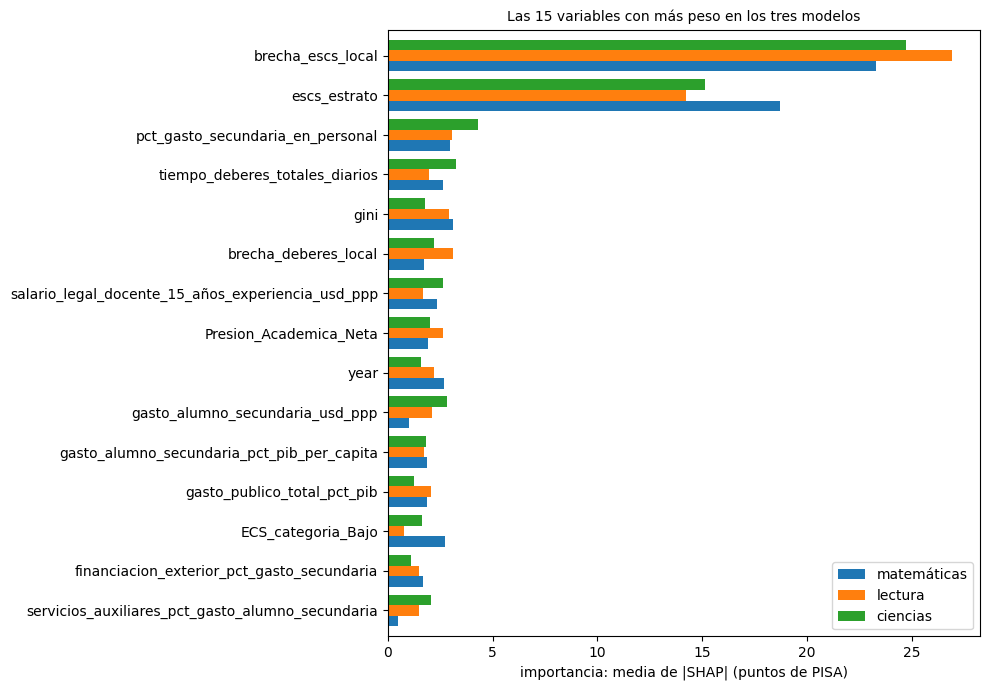

,matemáticas,lectura,ciencias
brecha_escs_local,23.30,26.91,24.74
escs_estrato,18.69,14.22,15.15
pct_gasto_secundaria_en_personal,2.95,3.06,4.28
tiempo_deberes_totales_diarios,2.64,1.95,3.26
gini,3.12,2.91,1.78
brecha_deberes_local,1.70,3.09,2.20
salario_legal_docente_15_años_experiencia_usd_ppp,2.33,1.68,2.60
Presion_Academica_Neta,1.93,2.64,1.98
year,2.68,2.17,1.60
gasto_alumno_secundaria_usd_ppp,1.00,2.11,2.80


In [5]:
explicadores_shap = {asignatura: shap.TreeExplainer(modelo) for asignatura, modelo in modelos.items()}   # se guardan al final, como en 04_inferencia_matematicas
explicaciones = {asignatura: explicador(X_test) for asignatura, explicador in explicadores_shap.items()}

# Importancia media (|SHAP| en puntos) de cada variable en cada asignatura, de mayor a menor según la media de las tres
importancia_shap = pd.DataFrame({asignatura: np.abs(explicacion.values).mean(axis=0) for asignatura, explicacion in explicaciones.items()}, index=variables_modelo)
importancia_shap = importancia_shap.loc[importancia_shap.mean(axis=1).sort_values(ascending=False).index]
principales = importancia_shap.head(15)
fig, ax = plt.subplots(figsize=(10, 7))
principales.iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.set_xlabel('importancia: media de |SHAP| (puntos de PISA)')
ax.set_title('Las 15 variables con más peso en los tres modelos', fontsize=10)
plt.tight_layout()
plt.show()
importancia_shap.round(2)

In [6]:
# Dirección del efecto: correlación entre el valor de la variable y su SHAP (positiva = valores altos suman puntos), para las 10 variables con más peso
principales_10 = importancia_shap.head(10).index
direccion_shap = pd.DataFrame({asignatura: [pd.Series(explicacion[:, variable].values).corr(pd.Series(explicacion[:, variable].data)) for variable in principales_10]
                               for asignatura, explicacion in explicaciones.items()}, index=principales_10)
direccion_shap.round(2)

,matemáticas,lectura,ciencias
brecha_escs_local,0.88,0.89,0.90
escs_estrato,0.92,0.91,0.92
pct_gasto_secundaria_en_personal,-0.76,-0.74,-0.74
tiempo_deberes_totales_diarios,-0.65,-0.56,-0.79
gini,-0.86,-0.27,-0.43
brecha_deberes_local,0.55,0.53,0.60
salario_legal_docente_15_años_experiencia_usd_ppp,0.29,0.68,0.52
Presion_Academica_Neta,0.10,-0.38,-0.44
year,-0.68,-0.70,-0.62
gasto_alumno_secundaria_usd_ppp,0.54,0.55,0.60


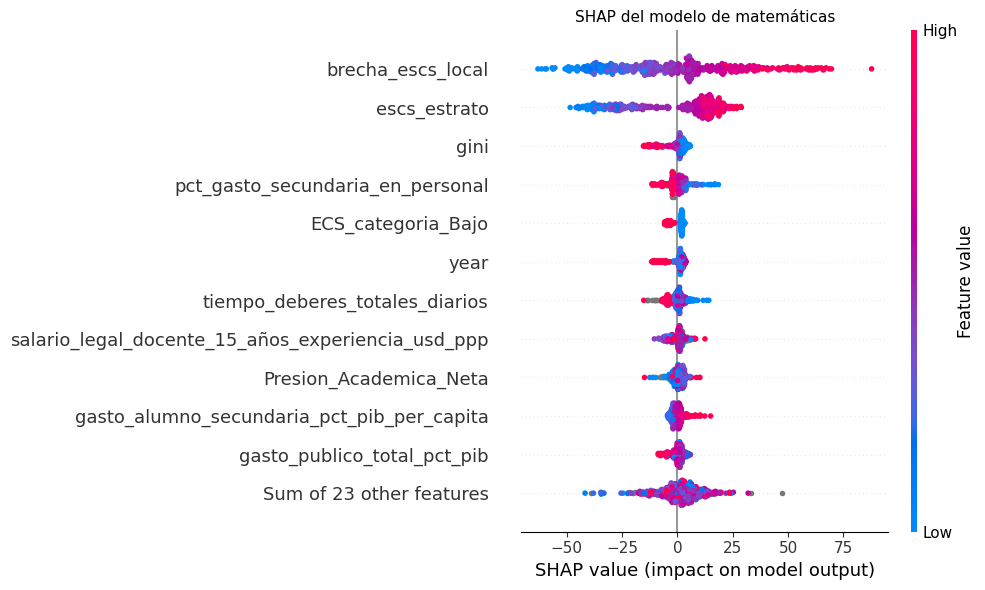

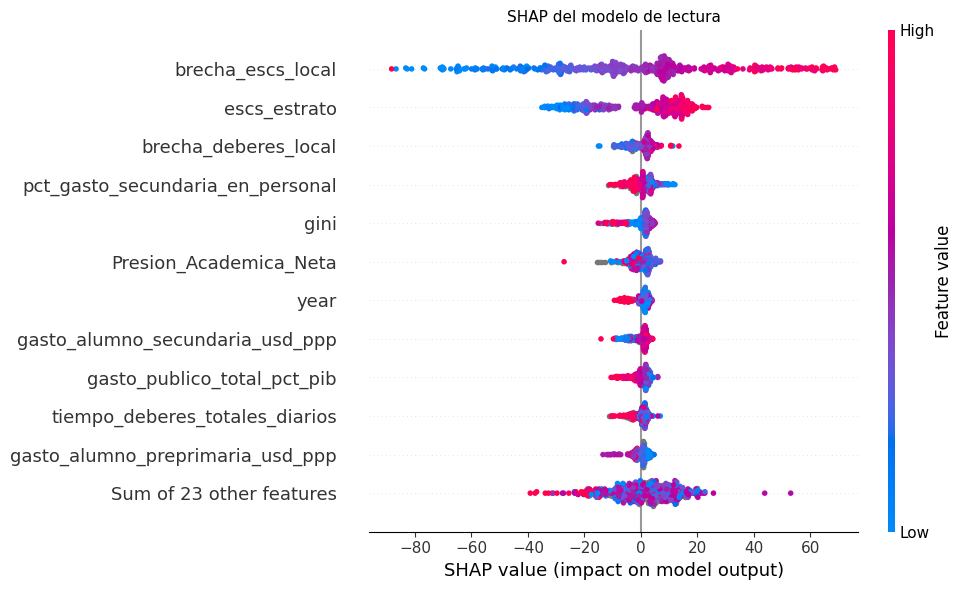

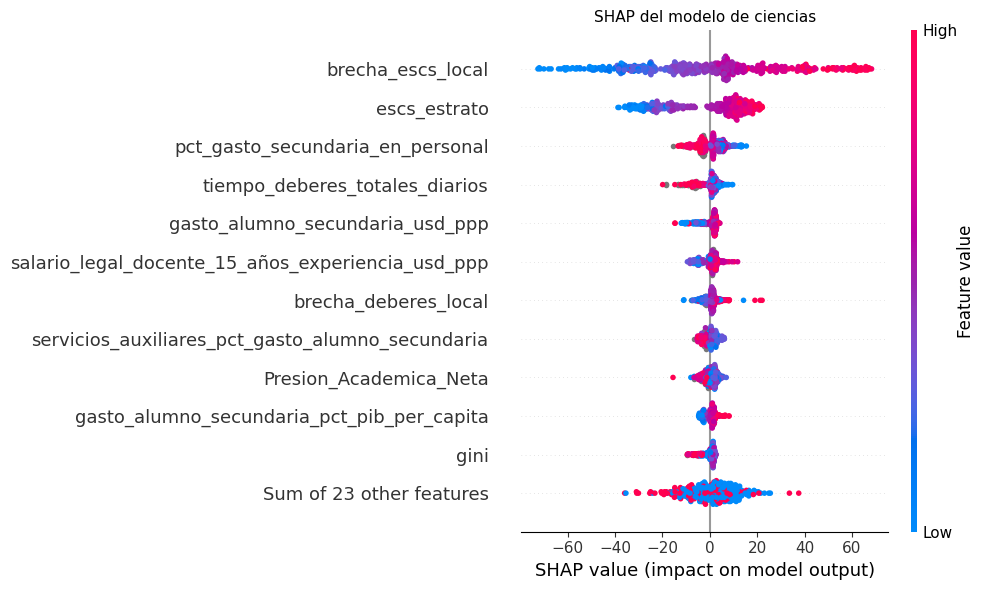

In [7]:
for asignatura, explicacion in explicaciones.items():
    shap.plots.beeswarm(explicacion, max_display=12, show=False, plot_size=(10, 6))
    plt.title(f'SHAP del modelo de {asignatura}', fontsize=11)
    plt.tight_layout()
    plt.show()

**Qué se ve.**

* **El nivel socioeconómico domina en las tres asignaturas**: `brecha_escs_local` (la posición del estrato dentro de su país) mueve de media entre 23,3 y 26,9 puntos y `escs_estrato` entre 14,2 y 18,7; ninguna otra variable pasa de 4,3 puntos. En las dos, los valores altos suman puntos (correlación entre el valor y su SHAP de 0,88 a 0,92).
* **El presupuesto y el contexto del país pesan poco** (como mucho 4,3 puntos). El que más, el % del gasto de secundaria en personal (de 3,0 a 4,3 puntos; los valores altos restan, correlación de −0,74 a −0,76). El Gini pesa de 1,8 a 3,1 puntos (más desigualdad resta, de −0,27 a −0,86), el salario docente con 15 años de experiencia de 1,7 a 2,6 (los valores altos suman, de 0,29 a 0,68) y el gasto por alumno de secundaria de 1,0 a 2,8 (más gasto suma, de 0,54 a 0,60). Es coherente con «Cuánta variación hay en cada variable»: el presupuesto es un dato de país, con unos 33 países distintos.
* **Deberes**: las horas de deberes pesan de 2,0 a 3,3 puntos y los valores altos restan (de −0,56 a −0,79); la brecha de deberes pesa de 1,7 a 3,1 puntos y los valores altos suman (de 0,53 a 0,60); la presión académica pesa de 1,9 a 2,6 puntos sin una dirección clara (de −0,44 a 0,10).
* **`year`** pesa de 1,6 a 2,7 puntos y las ediciones recientes restan (de −0,62 a −0,70): recoge la caída de 2022.
* **El perfil de país no pesa** (como mucho 0,33 puntos).

**Cautelas**: SHAP describe lo que ha aprendido el modelo, no efectos causales. Con la partición estratificada por país, el modelo ha visto en el train los mismos valores de las variables de país que hay en el test, así que puede usarlas para reconocer al país y no solo por lo que miden. Su peso se apoya en unos 33 países. Las variables correlacionadas se reparten la importancia (por eso se quitaron las redundantes), y la dirección se resume con una correlación lineal entre el valor y su SHAP.

## Guardado de los modelos

En `data/models`, con los nombres que ya usa el proyecto (sustituyen a los modelos entrenados con datos simulados): un modelo por asignatura (`modelo_xgb_math_opt.pkl`, `modelo_xgb_read_opt.pkl` y `modelo_xgb_scie_opt.pkl`). El test no se guarda. Son los modelos baseline, sin ajustar hiperparámetros.

Para el LLM se guardan en `agente_llm/data_llm` los tres modelos (con los mismos nombres), la lista de columnas que esperan (`columnas_modelo.pkl`, las de `X_test`; no el `X_test` entero) y los explicadores SHAP (`TreeExplainer`), como hace `04_inferencia_matematicas`: el de matemáticas con el nombre que ya usa el proyecto (`shap_explainer.pkl`) y los de lectura y ciencias como `shap_explainer_read.pkl` y `shap_explainer_scie.pkl`.

In [8]:
ruta_modelos = Path('../../data/models')
codigo_asignatura = {'matemáticas': 'math', 'lectura': 'read', 'ciencias': 'scie'}
for asignatura, modelo in modelos.items():
    joblib.dump(modelo, ruta_modelos / f'modelo_xgb_{codigo_asignatura[asignatura]}_opt.pkl')

# Comprobación: los ficheros se cargan y predicen lo mismo que los modelos en memoria
for asignatura, modelo in modelos.items():
    cargado = joblib.load(ruta_modelos / f'modelo_xgb_{codigo_asignatura[asignatura]}_opt.pkl')
    assert list(cargado.feature_names_in_) == list(X_test.columns)
    assert np.allclose(cargado.predict(X_test), modelo.predict(X_test))
print(f'3 modelos guardados en {ruta_modelos}')

# Para el LLM: los tres modelos y las columnas que esperan (las de X_test, no X_test entero)
ruta_datos_llm = Path('../../agente_llm/data_llm')
columnas_modelo = X_test.columns.tolist()
joblib.dump(columnas_modelo, ruta_datos_llm / 'columnas_modelo.pkl')
for asignatura, modelo in modelos.items():
    joblib.dump(modelo, ruta_datos_llm / f'modelo_xgb_{codigo_asignatura[asignatura]}_opt.pkl')
    cargado = joblib.load(ruta_datos_llm / f'modelo_xgb_{codigo_asignatura[asignatura]}_opt.pkl')
    assert np.allclose(cargado.predict(X_test[joblib.load(ruta_datos_llm / 'columnas_modelo.pkl')]), modelo.predict(X_test))
print(f'3 modelos y columnas_modelo.pkl ({len(columnas_modelo)} columnas) guardados en {ruta_datos_llm}')

# Explicadores SHAP, en la carpeta del LLM como hace 04_inferencia_matematicas
nombre_explicador = {'matemáticas': 'shap_explainer.pkl', 'lectura': 'shap_explainer_read.pkl', 'ciencias': 'shap_explainer_scie.pkl'}
for asignatura, explicador in explicadores_shap.items():
    joblib.dump(explicador, ruta_datos_llm / nombre_explicador[asignatura])
    cargado = joblib.load(ruta_datos_llm / nombre_explicador[asignatura])
    assert np.allclose(cargado.shap_values(X_test), explicaciones[asignatura].values)   # el fichero da los mismos valores SHAP
print(f"3 explicadores SHAP guardados en {ruta_datos_llm}: {', '.join(nombre_explicador.values())}")

3 modelos guardados en ..\..\data\models
3 modelos y columnas_modelo.pkl (34 columnas) guardados en ..\..\agente_llm\data_llm


3 explicadores SHAP guardados en ..\..\agente_llm\data_llm: shap_explainer.pkl, shap_explainer_read.pkl, shap_explainer_scie.pkl
